# Automated Malaria Parasite Detection in Thin Blood Smears Using a CNN
## Submission 2 — Pretrained CNNs, with and without fine-tuning

**Course:** CSE366 Artificial Intelligence  **Group:** 6

| Name | Student ID |
|---|---|
| Tahmid Aqib | 2024-1-60-225 |
| Rejoanur Rahman | 2024-1-60-245 |
| Mahmudur Rahaman Pial | 2024-1-60-177 |
| Sayem Siddiq | 2024-1-60-298 |

**Contents**
1. Experimental design and model choice
2. Setup (GPU, configuration, reproducibility)
3. Data: custom `Dataset` built on the Submission 1 split
4. Model builder, training loop, evaluation and plotting utilities
5. Six experiments: ResNet-50, DenseNet-121 and MobileNetV2, each **frozen** (without fine-tuning) and **fine-tuned**
6. Results summary table, comparison plots and discussion

## 1. Experimental design

### Two training modes per model

| Mode | Name in this notebook | What is trained | Learning rate |
|---|---|---|---|
| **Without fine-tuning** | `frozen` | Only the new classification head. The ImageNet backbone is used as a fixed feature extractor: its weights are frozen and its BatchNorm layers stay in inference mode, so their running statistics are not changed either. | Head 1e-3 |
| **With fine-tuning** | `finetune` | Every layer. The backbone starts from ImageNet weights and is adapted to blood-smear images. | Backbone 1e-4, head 1e-3 (discriminative learning rates, so the pretrained filters are adjusted gently) |

Each mode is a **separate run that starts from fresh ImageNet weights**, so the two modes are directly comparable. Every other setting is identical across all six runs: data split, augmentation, batch size, optimizer, loss, scheduler, epoch budget and seed. Any difference in results therefore comes from the architecture or the training mode.

### Why these three pretrained models

| Model | Design family | Approx. size | Why we chose it |
|---|---|---|---|
| **ResNet-50** | Residual network (skip connections) | ~25 M params | The standard transfer-learning baseline. Rajaraman et al. (2018) found it was the best pretrained feature extractor on this exact dataset (95.9% patient-level accuracy), so it gives us a published reference point for the frozen mode. |
| **DenseNet-121** | Densely connected network (feature reuse) | ~8 M params | Each layer receives the feature maps of all earlier layers. This reuse of fine, low-level features suits small texture details such as a stained parasite, and the model is widely used in medical imaging. It reaches ResNet-50-level accuracy with about a third of the parameters. |
| **MobileNetV2** | Lightweight, depthwise-separable convolutions with inverted residuals | ~3.5 M params | Designed for phones and edge devices. Malaria screening is often done with a smartphone attached to a microscope (this dataset was captured that way), so we test whether a small, fast model can match the heavy ones. This is also the closest pretrained model to the custom CNN we will build in Submission 3. |

The three models cover three different architectural ideas (residual, dense and mobile/efficient), so the comparison says something about design choices, not just about model size.

### Preventing overfitting and underfitting
* **Data augmentation** (training only): random rotation of the full 360°, horizontal and vertical flips, small shifts and zoom, and mild colour jitter. Cells have no natural orientation, and stain intensity varies between slides.
* **Regularisation:** dropout (0.3) in the new head and AdamW weight decay (1e-4).
* **Learning-rate scheduling:** `ReduceLROnPlateau` cuts the learning rate ×0.3 when validation loss stops improving for 3 epochs.
* **Early stopping with a minimum budget:** every run trains for **at least 30 epochs** (the syllabus requires 30–50) and at most **40**. After epoch 30, training stops if validation loss has not improved for 8 epochs.
* **Best-checkpoint restore:** the weights from the epoch with the lowest validation loss are used for testing, so late overfitting cannot affect the test score.
* The **test set is used only once per run**, after training is finished.

### GPU settings (RTX 4070, 12 GB)
Training uses **mixed precision** (FP16 autocast with gradient scaling) and the **channels-last** memory layout, which together roughly double throughput on Ada-generation tensor cores and halve activation memory. Data loading uses 6 CPU worker processes for training and 4 for evaluation, with a small prefetch queue, so the pipeline keeps the GPU busy while fitting in 16 GB of system RAM. With this setup a **batch size of 64** at 224×224 fits comfortably in 12 GB even for DenseNet-121, the most memory-hungry of the three. We keep 64 for every model so the comparison is fair. The notebook prints peak VRAM per run as evidence. The total runtime for all six runs should be roughly 2–3 hours.

## 2. Setup

Requirements: `torch>=2.3`, `kagglehub` (only if the images are not in `./data`), `torchvision>=0.18`, `scikit-learn`, `pandas`, `matplotlib`, `pillow`, `tqdm`. ImageNet weights are downloaded automatically by torchvision the first time (about 200 MB in total, cached in `~/.cache/torch`).

In [1]:
import os, json, time, random, platform, copy, gc
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display, Markdown

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision
from torchvision import models, transforms
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             precision_recall_fscore_support, roc_auc_score)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# ---- device -------------------------------------------------------------------------
if torch.cuda.is_available():
    device = torch.device("cuda")
    props = torch.cuda.get_device_properties(0)
    print(f"GPU: {props.name} | VRAM: {props.total_memory / 1024**3:.1f} GB | CUDA {torch.version.cuda}")
else:
    device = torch.device("cpu")
    print("WARNING: CUDA not available — running on CPU will be extremely slow.")

torch.backends.cudnn.benchmark = True            # pick the fastest conv algorithms for fixed 224x224 inputs
torch.backends.cuda.matmul.allow_tf32 = True     # TF32 on Ada tensor cores for any FP32 math
torch.backends.cudnn.allow_tf32 = True
USE_AMP = device.type == "cuda"                  # mixed precision only makes sense on GPU

print(f"Python {platform.python_version()} | torch {torch.__version__} | torchvision {torchvision.__version__}")

GPU: NVIDIA GeForce RTX 4070 | VRAM: 11.7 GB | CUDA 13.2
Python 3.15.0 | torch 2.15.0+cu132 | torchvision 0.29.2+cu132


In [2]:
# ---- configuration (identical for every run) -----------------------------------------
SEED          = 42
IMG_SIZE      = 224            # standard ImageNet input size
BATCH_SIZE    = 64             # fits all three models in 12 GB with AMP + channels_last
EVAL_BATCH    = 128            # no gradients at evaluation, so a larger batch is fine
MAX_EPOCHS    = 40             # syllabus: 30-50 epochs
MIN_EPOCHS    = 30             # early stopping is not allowed before this epoch
PATIENCE      = 8              # epochs without val-loss improvement before stopping (after MIN_EPOCHS)
LR_HEAD       = 1e-3
LR_BACKBONE   = 1e-4           # used only in fine-tune mode
WEIGHT_DECAY  = 1e-4
DROPOUT       = 0.3
NUM_WORKERS   = 6              # CPU worker processes for the training loader (Ryzen 7 7700: 8 cores / 16 threads)
EVAL_WORKERS  = 4              # workers for the validation / test loaders
PREFETCH      = 2              # batches queued per worker; kept low so the pipeline fits in 16 GB of RAM
NORMALIZATION = "imagenet"     # "imagenet" (correct for pretrained weights) or "dataset" (Submission 1 stats)
RETRAIN       = False          # False: reuse finished runs saved on disk (handy if the kernel restarts)

ARCHS = ["resnet50", "densenet121", "mobilenet_v2"]
MODES = ["frozen", "finetune"]
PRETTY = {"resnet50": "ResNet-50", "densenet121": "DenseNet-121", "mobilenet_v2": "MobileNetV2",
          "frozen": "Frozen (no fine-tuning)", "finetune": "Fine-tuned"}

CLASSES      = ["Parasitized", "Uninfected"]   # index 0 = Parasitized (the positive / disease class)
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}

# Image folder: use ./data if it exists, otherwise the kagglehub cache (where Submission 1 downloaded it).
if Path("./data").exists():
    DATA_DIR = Path("./data")
else:
    import kagglehub
    DATA_DIR = Path(kagglehub.dataset_download("iarunava/cell-images-for-detecting-malaria"))
SPLITS_CSV  = Path("./splits/splits.csv")
NORM_JSON   = Path("./splits/norm_stats.json")
CKPT_DIR    = Path("./checkpoints/sub2"); CKPT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR = Path("./results/sub2");     RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR     = Path("./figures/sub2");     FIG_DIR.mkdir(parents=True, exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

set_seed()

## 3. Data

### 3.1 Load the Submission 1 split
`splits/splits.csv` was created in Submission 1 by grouping cells by their **source smear photograph**, so no photograph contributes cells to more than one split. We load it as-is: no `ImageFolder` and no re-splitting. `relpath` is relative to the folder that holds the `Parasitized/` and `Uninfected/` sub-folders, which we locate automatically.

In [3]:
def find_class_root(root):
    # Return the shallowest folder that contains both class sub-folders (same helper as Submission 1).
    root = Path(root)
    candidates = [root] + sorted((d for d in root.rglob("*") if d.is_dir()), key=lambda p: len(p.parts))
    for p in candidates:
        if all((p / c).is_dir() for c in CLASSES):
            return p
    raise FileNotFoundError(f"No folder with {CLASSES} under {root.resolve()}")

IMG_ROOT = find_class_root(DATA_DIR)
splits = pd.read_csv(SPLITS_CSV)
assert {"relpath", "label", "split"} <= set(splits.columns), "splits.csv is missing required columns"

missing = [p for p in splits.relpath if not (IMG_ROOT / p).is_file()]
assert not missing, f"{len(missing)} files listed in splits.csv were not found, e.g. {missing[:3]}"

print("Image root:", IMG_ROOT.resolve())
tab = pd.crosstab(splits.split, splits.label, margins=True).reindex(["train", "val", "test", "All"])
display(tab)

train_df = splits[splits.split == "train"].reset_index(drop=True)
val_df   = splits[splits.split == "val"].reset_index(drop=True)
test_df  = splits[splits.split == "test"].reset_index(drop=True)

Image root: /home/taqib/.cache/kagglehub/datasets/iarunava/cell-images-for-detecting-malaria/versions/1/cell_images


label,Parasitized,Uninfected,All
split,,,
train,9834,9827,19661
val,1973,1976,3949
test,1972,1976,3948
All,13779,13779,27558


### 3.2 Custom PyTorch `Dataset` (saved to `malaria_data.py`)

The `Dataset` class and the `PadToSquare` transform are written from this cell into a small module, `malaria_data.py`, and then imported. This is needed for multi-process data loading on recent Python versions. From Python 3.14, Linux starts `DataLoader` worker processes with **forkserver** instead of **fork**, and a forkserver worker has to *import* every class it receives. A class defined only inside a notebook cell lives in the kernel's `__main__` and cannot be imported, which produces `AttributeError: module '__main__' has no attribute 'MalariaCellDataset'`. Keeping the classes in a module fixes this while leaving the full code visible here, and lets 6 training and 4 evaluation workers decode and augment images in parallel so the GPU is not left waiting.

Because cell crops are not square, `PadToSquare` pads each image to a square with black (matching the existing background) before resizing, so round cells are not stretched into ovals.

In [4]:
%%writefile malaria_data.py
# Dataset and transform helpers for the CSE366 malaria project (written from Submission2_Pretrained_Models.ipynb).
from pathlib import Path

import numpy as np
from PIL import Image
from torch.utils.data import Dataset


class PadToSquare:
    # Pad a PIL image to a square canvas with black, keeping it centred (preserves cell shape).
    def __call__(self, img):
        w, h = img.size
        s = max(w, h)
        canvas = Image.new("RGB", (s, s), (0, 0, 0))
        canvas.paste(img, ((s - w) // 2, (s - h) // 2))
        return canvas


class MalariaCellDataset(Dataset):
    # Loads the cell images listed in a split DataFrame (columns: relpath, label).
    # class_to_idx maps label names to integers, e.g. {"Parasitized": 0, "Uninfected": 1}.

    def __init__(self, frame, root, class_to_idx, transform=None):
        mapped = frame["label"].map(class_to_idx)
        if mapped.isna().any():
            raise ValueError(f"Unknown labels in splits.csv: {set(frame['label'][mapped.isna()])}")
        self.paths = [Path(root) / p for p in frame["relpath"]]
        self.labels = mapped.astype(int).to_numpy()
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        with Image.open(self.paths[idx]) as im:
            img = im.convert("RGB")            # guarantees 3 channels
        if self.transform is not None:
            img = self.transform(img)
        return img, int(self.labels[idx])

Writing malaria_data.py


In [5]:
import importlib, sys
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())             # make sure the notebook folder is importable
import malaria_data
importlib.reload(malaria_data)                  # pick up edits if the cell above is re-run
from malaria_data import MalariaCellDataset, PadToSquare
print("Loaded MalariaCellDataset and PadToSquare from", malaria_data.__file__)

Loaded MalariaCellDataset and PadToSquare from /home/taqib/Documents/cnnproject/malaria_data.py


### 3.3 Normalisation and transforms
The pretrained weights were learned on ImageNet images normalised with the ImageNet mean and standard deviation. To use those filters correctly we normalise with the same statistics. The training-set statistics from Submission 1 (`norm_stats.json`) are loaded and shown for reference; we will use them for the from-scratch CNN in Submission 3, and switching `NORMALIZATION = "dataset"` uses them here.

In [6]:
IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
with open(NORM_JSON) as f:
    ds_stats = json.load(f)
print("Submission 1 train-set stats:", ds_stats)

MEAN, STD = (IMAGENET_MEAN, IMAGENET_STD) if NORMALIZATION == "imagenet" else (ds_stats["mean"], ds_stats["std"])
print(f"Using {NORMALIZATION} normalisation -> mean={MEAN}, std={STD}")

train_tf = transforms.Compose([
    PadToSquare(),
    transforms.Resize((IMG_SIZE, IMG_SIZE), antialias=True),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomAffine(degrees=180, translate=(0.05, 0.05), scale=(0.95, 1.05), fill=0),
    transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1, hue=0.02),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([
    PadToSquare(),
    transforms.Resize((IMG_SIZE, IMG_SIZE), antialias=True),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

Submission 1 train-set stats: {'resolution': 128, 'mean': [0.5296, 0.4241, 0.453], 'std': [0.3359, 0.2717, 0.2871], 'note': 'computed on TRAIN split only, pixels scaled to [0,1], includes black background'}
Using imagenet normalisation -> mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]


### 3.4 Datasets and data loaders

In [7]:
train_ds = MalariaCellDataset(train_df, IMG_ROOT, CLASS_TO_IDX, train_tf)
val_ds   = MalariaCellDataset(val_df,   IMG_ROOT, CLASS_TO_IDX, eval_tf)
test_ds  = MalariaCellDataset(test_df,  IMG_ROOT, CLASS_TO_IDX, eval_tf)
print(f"train={len(train_ds):,}  val={len(val_ds):,}  test={len(test_ds):,}")

def make_loaders(seed=SEED):
    # Fresh loaders per run with a seeded generator, so every run sees the same shuffling order.
    g = torch.Generator(); g.manual_seed(seed)

    def opts(workers):
        o = dict(num_workers=workers, pin_memory=device.type == "cuda")
        if workers > 0:
            # persistent workers are reused across epochs instead of being restarted every epoch
            o.update(persistent_workers=True, prefetch_factor=PREFETCH)
        return o

    train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True, generator=g, **opts(NUM_WORKERS))
    val_loader   = DataLoader(val_ds,   batch_size=EVAL_BATCH, shuffle=False, **opts(EVAL_WORKERS))
    test_loader  = DataLoader(test_ds,  batch_size=EVAL_BATCH, shuffle=False, **opts(EVAL_WORKERS))
    return train_loader, val_loader, test_loader

train=19,661  val=3,949  test=3,948


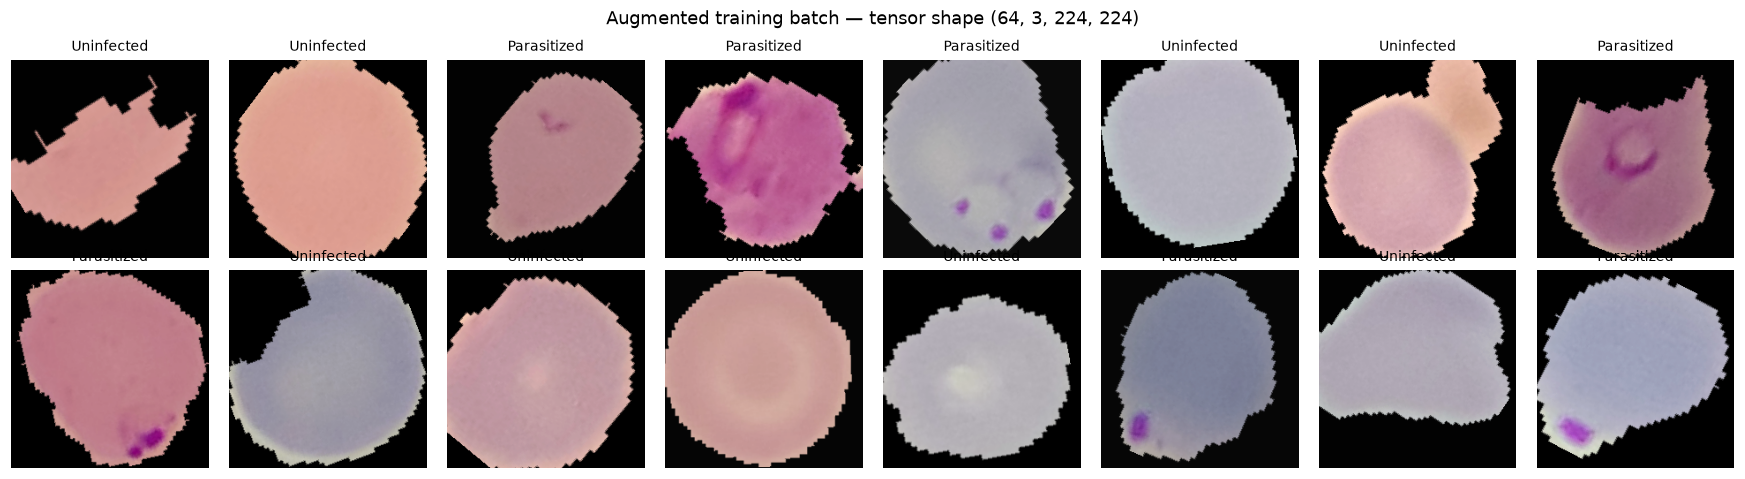

32

In [8]:
# Sanity check: one augmented training batch (de-normalised for display)
tl, _, _ = make_loaders()
xb, yb = next(iter(tl))
mean_t, std_t = torch.tensor(MEAN).view(3, 1, 1), torch.tensor(STD).view(3, 1, 1)
fig, axes = plt.subplots(2, 8, figsize=(16, 4.4))
for ax, x, y in zip(axes.ravel(), xb[:16], yb[:16]):
    ax.imshow((x * std_t + mean_t).clamp(0, 1).permute(1, 2, 0).numpy())
    ax.set_title(CLASSES[y], fontsize=9); ax.axis("off")
fig.suptitle(f"Augmented training batch — tensor shape {tuple(xb.shape)}")
plt.tight_layout(); plt.savefig(FIG_DIR / "augmented_batch.png"); plt.show()
del tl, _
gc.collect()

## 4. Model builder, training loop and evaluation

**Model builder.** It loads ImageNet weights and replaces the 1000-class ImageNet classifier with a new head (`Dropout → Linear(features, 2)`). In `frozen` mode every backbone parameter gets `requires_grad=False`, so only the head is optimised. No backbone gradients are computed, which also makes these runs much faster.

In [9]:
def build_model(arch, mode):
    # Return (model, head) with ImageNet weights and a new 2-class head.
    if arch == "resnet50":
        m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
        m.fc = nn.Sequential(nn.Dropout(DROPOUT), nn.Linear(m.fc.in_features, len(CLASSES)))
        head = m.fc
    elif arch == "densenet121":
        m = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
        m.classifier = nn.Sequential(nn.Dropout(DROPOUT), nn.Linear(m.classifier.in_features, len(CLASSES)))
        head = m.classifier
    elif arch == "mobilenet_v2":
        m = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V2)
        m.classifier = nn.Sequential(nn.Dropout(DROPOUT), nn.Linear(m.last_channel, len(CLASSES)))
        head = m.classifier
    else:
        raise ValueError(arch)

    head_ids = {id(p) for p in head.parameters()}
    if mode == "frozen":
        for p in m.parameters():
            p.requires_grad = id(p) in head_ids      # only the new head learns
    elif mode != "finetune":
        raise ValueError(mode)
    return m, head

def make_optimizer(model, head, mode):
    head_ids = {id(p) for p in head.parameters()}
    if mode == "frozen":
        groups = [{"params": list(head.parameters()), "lr": LR_HEAD}]
    else:  # discriminative learning rates: gentle on pretrained filters, faster on the new head
        backbone = [p for p in model.parameters() if id(p) not in head_ids]
        groups = [{"params": backbone, "lr": LR_BACKBONE}, {"params": list(head.parameters()), "lr": LR_HEAD}]
    opt = torch.optim.AdamW(groups, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", factor=0.3, patience=3, min_lr=1e-7)
    return opt, sched

def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

**Training loop.** Each epoch runs one pass over the training set with mixed precision, then evaluates on the validation set. We log loss, accuracy and learning rate, step the plateau scheduler on validation loss, keep the best-validation-loss weights, and apply early stopping only after `MIN_EPOCHS`. In `frozen` mode the backbone BatchNorm layers stay in `eval()` mode, so the ImageNet statistics are truly frozen.

In [10]:
def set_bn_eval(model):
    for mod in model.modules():
        if isinstance(mod, nn.modules.batchnorm._BatchNorm):
            mod.eval()

def to_device(x, y):
    x = x.to(device, non_blocking=True, memory_format=torch.channels_last)
    return x, y.to(device, non_blocking=True)

def run_epoch(model, loader, criterion, optimizer=None, scaler=None, freeze_bn=False):
    # One pass over `loader`. Trains if an optimizer is given, otherwise evaluates. Returns (loss, accuracy).
    training = optimizer is not None
    model.train(training)
    if training and freeze_bn:
        set_bn_eval(model)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = to_device(x, y)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
                logits = model(x)
                loss = criterion(logits, y)
            if training:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * y.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            n += y.size(0)
    return total_loss / n, correct / n

def sync():
    if device.type == "cuda":
        torch.cuda.synchronize()

def train_model(model, head, mode, train_loader, val_loader, run_name):
    criterion = nn.CrossEntropyLoss()
    optimizer, scheduler = make_optimizer(model, head, mode)
    scaler = torch.amp.GradScaler(device.type, enabled=USE_AMP)

    history = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc", "lr"]}
    best_loss, best_epoch, best_state, wait = float("inf"), 0, None, 0

    sync(); t0 = time.perf_counter()
    for epoch in range(1, MAX_EPOCHS + 1):
        te = time.perf_counter()
        tr_loss, tr_acc = run_epoch(model, train_loader, criterion, optimizer, scaler, freeze_bn=(mode == "frozen"))
        va_loss, va_acc = run_epoch(model, val_loader, criterion)
        lr_now = optimizer.param_groups[-1]["lr"]          # head LR (backbone LR is 10x lower in fine-tune mode)
        scheduler.step(va_loss)

        for k, v in zip(history, [tr_loss, tr_acc, va_loss, va_acc, lr_now]):
            history[k].append(v)

        improved = va_loss < best_loss - 1e-4
        if improved:
            best_loss, best_epoch, wait = va_loss, epoch, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1

        print(f"[{run_name}] ep {epoch:02d}/{MAX_EPOCHS} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
              f"val loss {va_loss:.4f} acc {va_acc:.4f} | lr {lr_now:.1e} | {time.perf_counter() - te:5.1f}s"
              + ("  *best*" if improved else ""))

        if epoch >= MIN_EPOCHS and wait >= PATIENCE:
            print(f"Early stopping at epoch {epoch}: no val-loss improvement for {PATIENCE} epochs.")
            break
    sync(); train_time = time.perf_counter() - t0

    model.load_state_dict(best_state)                       # restore the best-validation weights
    torch.save(best_state, CKPT_DIR / f"{run_name}.pt")
    return history, best_epoch, train_time

**Evaluation and plots.** Testing time is the wall-clock time to predict the whole test set (data loading included, after one GPU warm-up batch). We also report it per image. Per-class precision, recall and F1 come from scikit-learn's `classification_report`. The confusion matrix shows counts and row percentages.

In [11]:
@torch.inference_mode()
def predict(model, loader):
    model.eval()
    x0, _ = next(iter(loader))                               # warm-up (cudnn autotune, lazy init)
    with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
        model(x0.to(device, memory_format=torch.channels_last))
    sync(); t0 = time.perf_counter()
    probs, ys = [], []
    for x, y in loader:
        x, _ = to_device(x, y)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(x)
        probs.append(torch.softmax(logits.float(), 1).cpu()); ys.append(y)
    sync(); test_time = time.perf_counter() - t0
    probs = torch.cat(probs).numpy(); y_true = torch.cat(ys).numpy()
    return y_true, probs.argmax(1), probs, test_time

def plot_curves(history, best_epoch, title, path):
    ep = np.arange(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    axes[0].plot(ep, history["train_acc"], "o-", ms=3, label="Train")
    axes[0].plot(ep, history["val_acc"], "s-", ms=3, label="Validation")
    axes[0].set_title(f"{title} — Accuracy"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Accuracy")
    axes[1].plot(ep, history["train_loss"], "o-", ms=3, label="Train")
    axes[1].plot(ep, history["val_loss"], "s-", ms=3, label="Validation")
    axes[1].set_title(f"{title} — Loss"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Cross-entropy loss")
    for ax in axes:
        ax.axvline(best_epoch, color="grey", ls="--", lw=1, label=f"Best epoch ({best_epoch})")
        ax.grid(alpha=.3); ax.legend()
    plt.tight_layout(); plt.savefig(path); plt.show()

def plot_confusion(cm, title, path):
    pct = cm / cm.sum(axis=1, keepdims=True)
    fig, ax = plt.subplots(figsize=(5, 4.3))
    im = ax.imshow(cm, cmap="Blues"); plt.colorbar(im, ax=ax, fraction=.046)
    ax.set_xticks(range(len(CLASSES))); ax.set_xticklabels(CLASSES)
    ax.set_yticks(range(len(CLASSES))); ax.set_yticklabels(CLASSES)
    ax.set_xlabel("Predicted label"); ax.set_ylabel("True label"); ax.set_title(f"{title}\nConfusion matrix (test set)")
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, f"{cm[i, j]:,}\n({pct[i, j]:.1%})", ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=11)
    plt.tight_layout(); plt.savefig(path); plt.show()

**One function per experiment.** `run_experiment(arch, mode)` builds the model, trains it (or reloads a finished run when `RETRAIN=False`), evaluates it on the test set and prints all the required outputs. Each experiment in Section 5 is a single call to this function.

In [12]:
def run_experiment(arch, mode):
    run_name = f"{arch}_{mode}"
    title = f"{PRETTY[arch]} — {PRETTY[mode]}"
    res_path, ckpt_path = RESULTS_DIR / f"{run_name}.json", CKPT_DIR / f"{run_name}.pt"
    set_seed()
    train_loader, val_loader, test_loader = make_loaders()

    model, head = build_model(arch, mode)
    model = model.to(device, memory_format=torch.channels_last)
    total_p, train_p = count_params(model)
    print(f"{title}\nParameters: total {total_p:,} | trainable {train_p:,} ({train_p / total_p:.1%})")
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats()

    if not RETRAIN and res_path.exists() and ckpt_path.exists():
        saved = json.load(open(res_path))
        history, best_epoch, train_time = saved["history"], saved["best_epoch"], saved["train_time_s"]
        model.load_state_dict(torch.load(ckpt_path, map_location=device))
        print(f"Loaded finished run from disk (set RETRAIN=True to train again).")
    else:
        history, best_epoch, train_time = train_model(model, head, mode, train_loader, val_loader, run_name)
    peak_gb = torch.cuda.max_memory_allocated() / 1024**3 if device.type == "cuda" else float("nan")
    del train_loader, val_loader                              # stop train/val workers to free RAM before testing
    gc.collect()

    # ---- test-set evaluation (used once, with the best-validation weights) ----
    y_true, y_pred, probs, test_time = predict(model, test_loader)
    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1], zero_division=0)
    macro = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    auc = roc_auc_score((y_true == 0).astype(int), probs[:, 0])   # Parasitized = positive class
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    # ---- required outputs ----
    epochs_run = len(history["train_loss"])
    print(f"\nEpochs run: {epochs_run} | best epoch (lowest val loss): {best_epoch} | peak GPU memory: {peak_gb:.2f} GB")
    print(f"TRAINING TIME: {train_time / 60:.2f} min ({train_time / epochs_run:.1f} s/epoch)")
    print(f"TESTING TIME : {test_time:.2f} s for {len(y_true):,} images ({1000 * test_time / len(y_true):.3f} ms/image)")
    gap = history["train_acc"][best_epoch - 1] - history["val_acc"][best_epoch - 1]
    fit = ("possible underfitting (low validation accuracy)" if history["val_acc"][best_epoch - 1] < 0.90
           else "good fit" if abs(gap) < 0.02 else "mild overfitting (handled by best-checkpoint restore)" if gap > 0
           else "validation above train (expected with train-time augmentation + dropout)")
    print(f"Train-val accuracy gap at best epoch: {gap * 100:+.2f} pp -> {fit}")

    plot_curves(history, best_epoch, title, FIG_DIR / f"{run_name}_curves.png")
    print(f"\nClassification report — {title} (test set)\n")
    print(classification_report(y_true, y_pred, target_names=CLASSES, digits=4, zero_division=0))
    print(f"ROC-AUC (Parasitized as positive): {auc:.4f}")
    plot_confusion(cm, title, FIG_DIR / f"{run_name}_confusion.png")

    summary = {
        "run": run_name, "model": PRETTY[arch], "mode": PRETTY[mode],
        "total_params": total_p, "trainable_params": train_p,
        "epochs_run": epochs_run, "best_epoch": best_epoch,
        "train_time_s": train_time, "test_time_s": test_time, "ms_per_image": 1000 * test_time / len(y_true),
        "peak_gpu_gb": peak_gb,
        "test_accuracy": acc, "macro_precision": macro[0], "macro_recall": macro[1], "macro_f1": macro[2],
        "precision_parasitized": prec[0], "recall_parasitized": rec[0], "f1_parasitized": f1[0],
        "precision_uninfected": prec[1], "recall_uninfected": rec[1], "f1_uninfected": f1[1],
        "auc": auc, "confusion_matrix": cm.tolist(),
        "best_val_acc": history["val_acc"][best_epoch - 1], "best_val_loss": history["val_loss"][best_epoch - 1],
        "history": history,
    }
    json.dump(summary, open(res_path, "w"), indent=1)

    del model, head, test_loader
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return summary

## 5. Experiments

Each run prints the per-epoch log, training and testing time, accuracy and loss curves (train vs validation), the classification report and the test-set confusion matrix.

### 5.1 ResNet-50 — without fine-tuning (frozen feature extractor)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /home/taqib/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|████████████████████████████████████████████| 97.8M/97.8M [00:02<00:00, 46.8MB/s]


ResNet-50 — Frozen (no fine-tuning)
Parameters: total 23,512,130 | trainable 4,098 (0.0%)
[resnet50_frozen] ep 01/40 | train loss 0.3305 acc 0.8663 | val loss 0.2612 acc 0.9053 | lr 1.0e-03 |  31.8s  *best*
[resnet50_frozen] ep 02/40 | train loss 0.2452 acc 0.9064 | val loss 0.2313 acc 0.9169 | lr 1.0e-03 |  17.5s  *best*
[resnet50_frozen] ep 03/40 | train loss 0.2292 acc 0.9135 | val loss 0.2157 acc 0.9228 | lr 1.0e-03 |  15.8s  *best*
[resnet50_frozen] ep 04/40 | train loss 0.2211 acc 0.9168 | val loss 0.2024 acc 0.9293 | lr 1.0e-03 |  15.1s  *best*
[resnet50_frozen] ep 05/40 | train loss 0.2127 acc 0.9229 | val loss 0.1958 acc 0.9326 | lr 1.0e-03 |  14.9s  *best*
[resnet50_frozen] ep 06/40 | train loss 0.2124 acc 0.9209 | val loss 0.1933 acc 0.9334 | lr 1.0e-03 |  14.9s  *best*
[resnet50_frozen] ep 07/40 | train loss 0.2078 acc 0.9221 | val loss 0.1894 acc 0.9344 | lr 1.0e-03 |  15.3s  *best*
[resnet50_frozen] ep 08/40 | train loss 0.2038 acc 0.9240 | val loss 0.1888 acc 0.9329 | lr

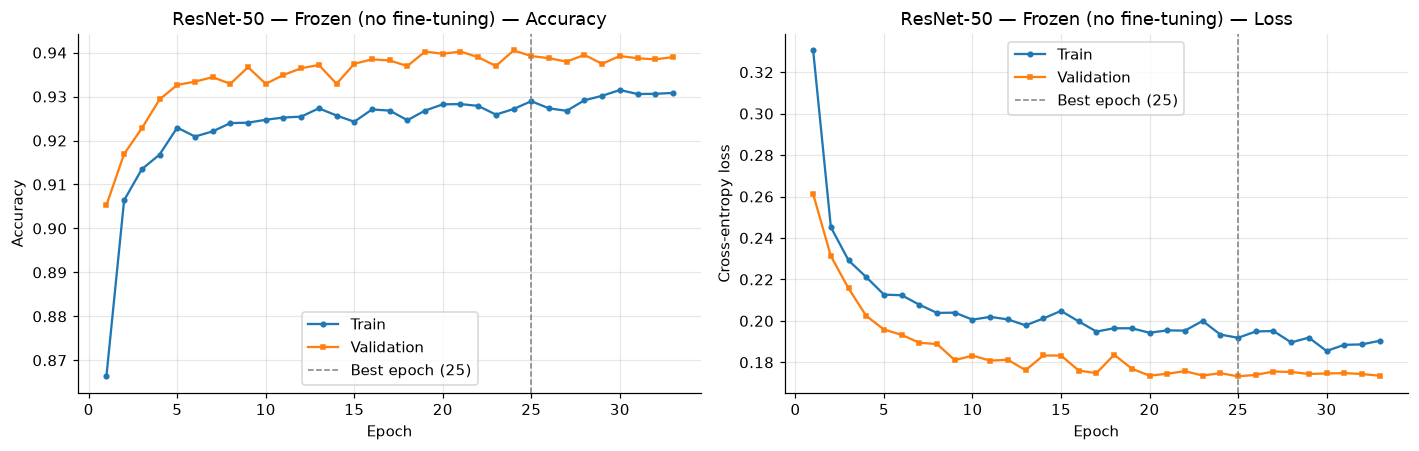


Classification report — ResNet-50 — Frozen (no fine-tuning) (test set)

              precision    recall  f1-score   support

 Parasitized     0.9412    0.9260    0.9335      1972
  Uninfected     0.9273    0.9423    0.9347      1976

    accuracy                         0.9341      3948
   macro avg     0.9343    0.9341    0.9341      3948
weighted avg     0.9343    0.9341    0.9341      3948

ROC-AUC (Parasitized as positive): 0.9781


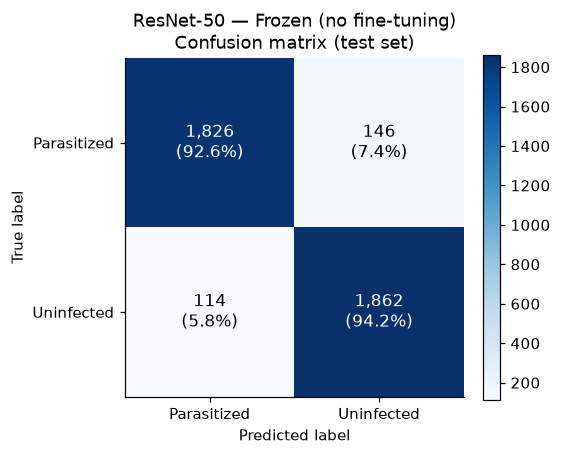

In [13]:
res_resnet50_frozen = run_experiment("resnet50", "frozen")

### 5.2 ResNet-50 — with fine-tuning (all layers trained)

ResNet-50 — Fine-tuned
Parameters: total 23,512,130 | trainable 23,512,130 (100.0%)
[resnet50_finetune] ep 01/40 | train loss 0.1360 acc 0.9508 | val loss 0.0930 acc 0.9689 | lr 1.0e-03 |  41.5s  *best*
[resnet50_finetune] ep 02/40 | train loss 0.0952 acc 0.9681 | val loss 0.0916 acc 0.9673 | lr 1.0e-03 |  28.3s  *best*
[resnet50_finetune] ep 03/40 | train loss 0.0862 acc 0.9691 | val loss 0.0864 acc 0.9696 | lr 1.0e-03 |  29.2s  *best*
[resnet50_finetune] ep 04/40 | train loss 0.0772 acc 0.9725 | val loss 0.0863 acc 0.9704 | lr 1.0e-03 |  28.4s  *best*
[resnet50_finetune] ep 05/40 | train loss 0.0772 acc 0.9733 | val loss 0.0746 acc 0.9747 | lr 1.0e-03 |  29.0s  *best*
[resnet50_finetune] ep 06/40 | train loss 0.0757 acc 0.9732 | val loss 0.0845 acc 0.9699 | lr 1.0e-03 |  29.3s
[resnet50_finetune] ep 07/40 | train loss 0.0687 acc 0.9749 | val loss 0.0852 acc 0.9737 | lr 1.0e-03 |  29.0s
[resnet50_finetune] ep 08/40 | train loss 0.0682 acc 0.9759 | val loss 0.0719 acc 0.9744 | lr 1.0e-

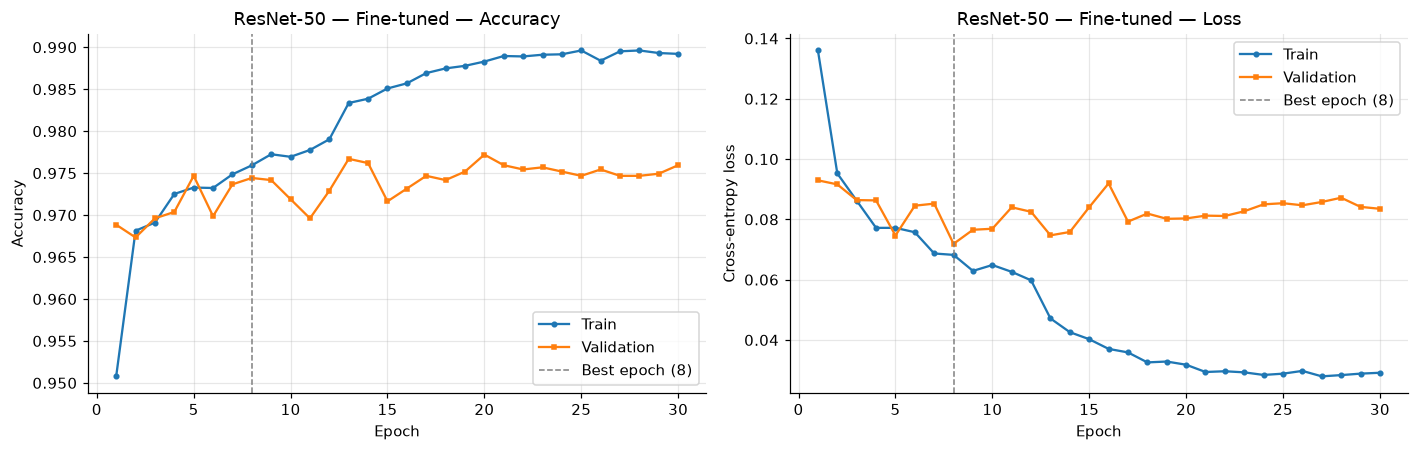


Classification report — ResNet-50 — Fine-tuned (test set)

              precision    recall  f1-score   support

 Parasitized     0.9741    0.9716    0.9728      1972
  Uninfected     0.9717    0.9742    0.9730      1976

    accuracy                         0.9729      3948
   macro avg     0.9729    0.9729    0.9729      3948
weighted avg     0.9729    0.9729    0.9729      3948

ROC-AUC (Parasitized as positive): 0.9964


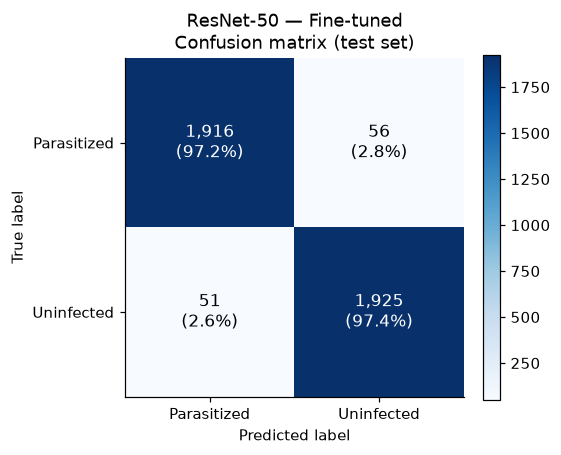

In [14]:
res_resnet50_finetune = run_experiment("resnet50", "finetune")

### 5.3 DenseNet-121 — without fine-tuning (frozen feature extractor)

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /home/taqib/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|████████████████████████████████████████████| 30.8M/30.8M [00:03<00:00, 10.6MB/s]

DenseNet-121 — Frozen (no fine-tuning)
Parameters: total 6,955,906 | trainable 2,050 (0.0%)


[densenet121_frozen] ep 01/40 | train loss 0.3379 acc 0.8548 | val loss 0.3028 acc 0.8876 | lr 1.0e-03 |  26.6s  *best*
[densenet121_frozen] ep 02/40 | train loss 0.2707 acc 0.8905 | val loss 0.2261 acc 0.9200 | lr 1.0e-03 |  15.9s  *best*
[densenet121_frozen] ep 03/40 | train loss 0.2586 acc 0.8975 | val loss 0.2170 acc 0.9238 | lr 1.0e-03 |  15.6s  *best*
[densenet121_frozen] ep 04/40 | train loss 0.2530 acc 0.8973 | val loss 0.2107 acc 0.9205 | lr 1.0e-03 |  14.5s  *best*
[densenet121_frozen] ep 05/40 | train loss 0.2512 acc 0.9013 | val loss 0.2075 acc 0.9286 | lr 1.0e-03 |  14.5s  *best*
[densenet121_frozen] ep 06/40 | train loss 0.2499 acc 0.9013 | val loss 0.2230 acc 0.9200 | lr 1.0e-03 |  14.9s
[densenet121_frozen] ep 07/40 | train loss 0.2496 acc 0.9002 | val loss 0.2001 acc 0.9276 | lr 1.0e-03 |  15.9s  *best*
[densenet121_frozen] ep 08/40 | train loss 0.2505 acc 0.9003 | val loss 0.1980 acc 0.9293 | lr 1.0e-03 |  15.0s  *best*
[densenet121_frozen] ep 09/40 | train loss 0.247

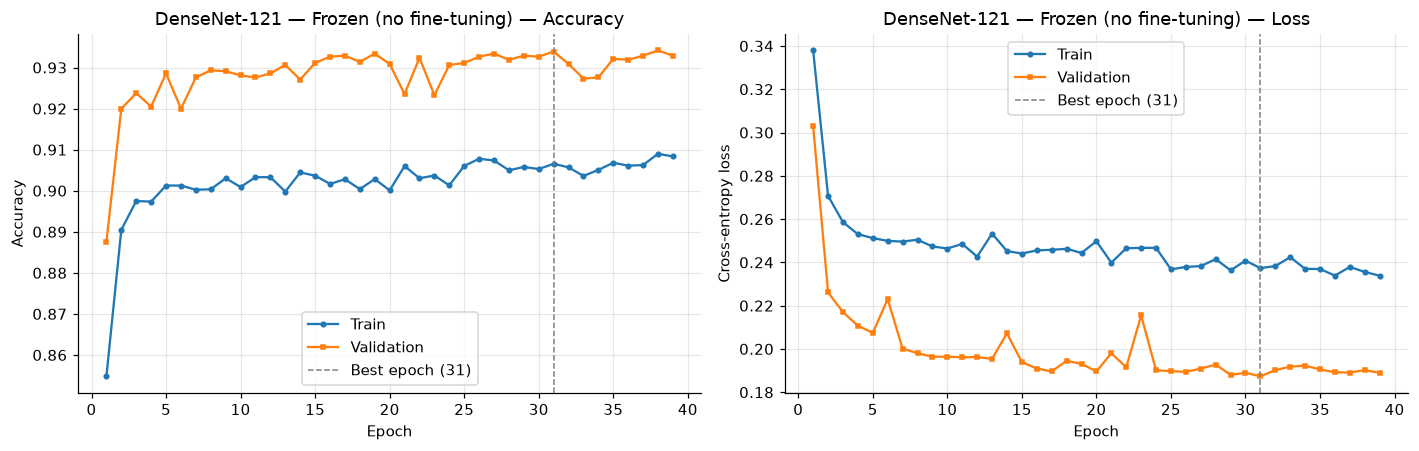


Classification report — DenseNet-121 — Frozen (no fine-tuning) (test set)

              precision    recall  f1-score   support

 Parasitized     0.9341    0.9128    0.9233      1972
  Uninfected     0.9149    0.9357    0.9252      1976

    accuracy                         0.9243      3948
   macro avg     0.9245    0.9243    0.9243      3948
weighted avg     0.9245    0.9243    0.9243      3948

ROC-AUC (Parasitized as positive): 0.9757


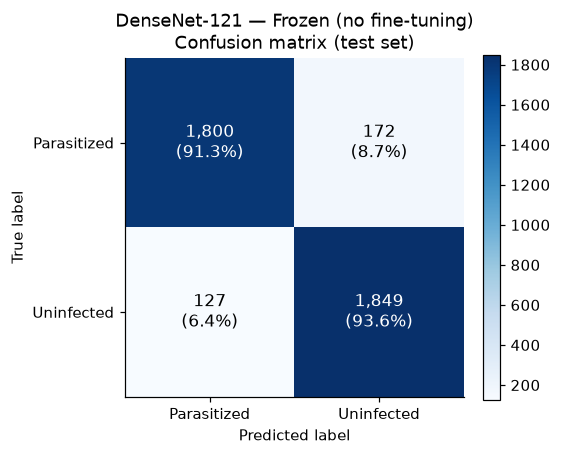

In [15]:
res_densenet121_frozen = run_experiment("densenet121", "frozen")

### 5.4 DenseNet-121 — with fine-tuning (all layers trained)

DenseNet-121 — Fine-tuned
Parameters: total 6,955,906 | trainable 6,955,906 (100.0%)
[densenet121_finetune] ep 01/40 | train loss 0.1287 acc 0.9522 | val loss 0.0952 acc 0.9689 | lr 1.0e-03 |  49.3s  *best*
[densenet121_finetune] ep 02/40 | train loss 0.0974 acc 0.9663 | val loss 0.0870 acc 0.9704 | lr 1.0e-03 |  32.2s  *best*
[densenet121_finetune] ep 03/40 | train loss 0.0856 acc 0.9685 | val loss 0.0843 acc 0.9711 | lr 1.0e-03 |  32.1s  *best*
[densenet121_finetune] ep 04/40 | train loss 0.0839 acc 0.9702 | val loss 0.0790 acc 0.9719 | lr 1.0e-03 |  32.2s  *best*
[densenet121_finetune] ep 05/40 | train loss 0.0816 acc 0.9708 | val loss 0.0726 acc 0.9764 | lr 1.0e-03 |  32.3s  *best*
[densenet121_finetune] ep 06/40 | train loss 0.0773 acc 0.9726 | val loss 0.0745 acc 0.9727 | lr 1.0e-03 |  32.1s
[densenet121_finetune] ep 07/40 | train loss 0.0717 acc 0.9735 | val loss 0.0820 acc 0.9734 | lr 1.0e-03 |  32.4s
[densenet121_finetune] ep 08/40 | train loss 0.0731 acc 0.9731 | val loss 0.0

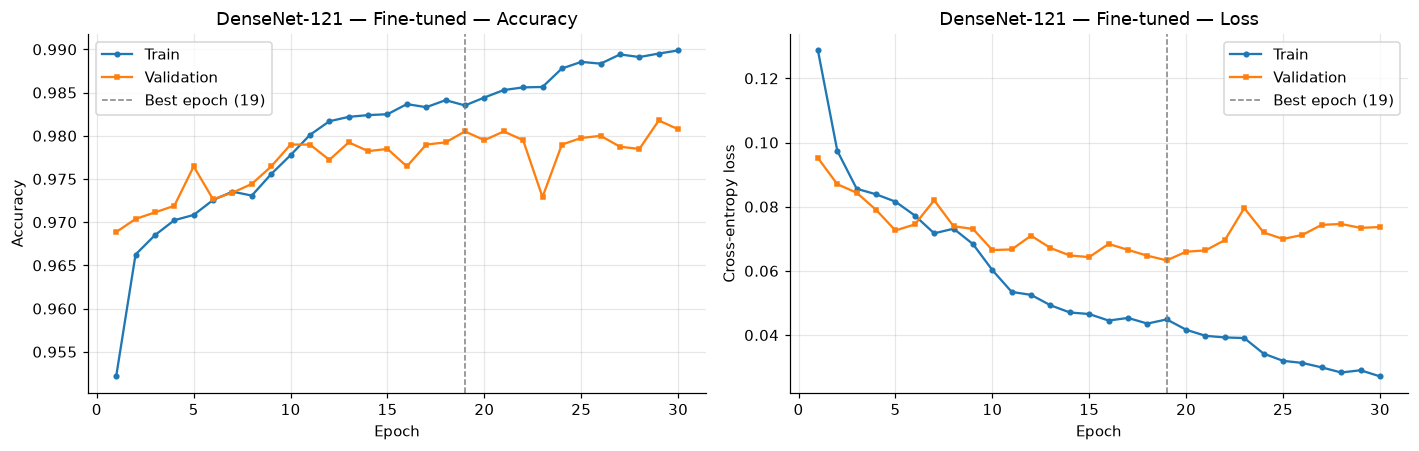


Classification report — DenseNet-121 — Fine-tuned (test set)

              precision    recall  f1-score   support

 Parasitized     0.9806    0.9731    0.9768      1972
  Uninfected     0.9734    0.9808    0.9771      1976

    accuracy                         0.9770      3948
   macro avg     0.9770    0.9769    0.9769      3948
weighted avg     0.9770    0.9770    0.9769      3948

ROC-AUC (Parasitized as positive): 0.9968


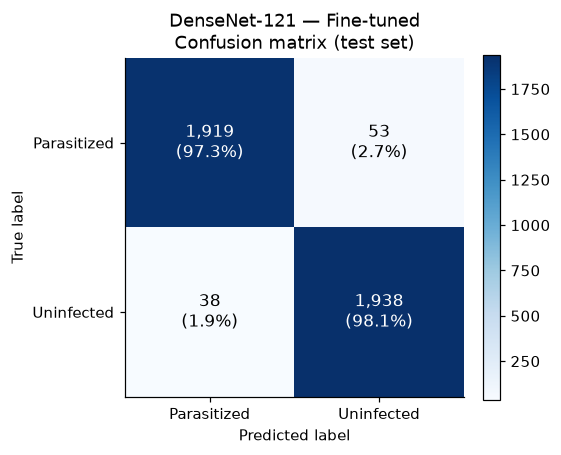

In [16]:
res_densenet121_finetune = run_experiment("densenet121", "finetune")

### 5.5 MobileNetV2 — without fine-tuning (frozen feature extractor)

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /home/taqib/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|████████████████████████████████████████████| 13.6M/13.6M [00:01<00:00, 9.44MB/s]

MobileNetV2 — Frozen (no fine-tuning)
Parameters: total 2,226,434 | trainable 2,562 (0.1%)


[mobilenet_v2_frozen] ep 01/40 | train loss 0.3486 acc 0.8571 | val loss 0.2328 acc 0.9119 | lr 1.0e-03 |  26.1s  *best*
[mobilenet_v2_frozen] ep 02/40 | train loss 0.2607 acc 0.9004 | val loss 0.2038 acc 0.9240 | lr 1.0e-03 |  13.3s  *best*
[mobilenet_v2_frozen] ep 03/40 | train loss 0.2447 acc 0.9070 | val loss 0.1946 acc 0.9293 | lr 1.0e-03 |  13.2s  *best*
[mobilenet_v2_frozen] ep 04/40 | train loss 0.2391 acc 0.9096 | val loss 0.1846 acc 0.9354 | lr 1.0e-03 |  13.4s  *best*
[mobilenet_v2_frozen] ep 05/40 | train loss 0.2352 acc 0.9128 | val loss 0.1830 acc 0.9382 | lr 1.0e-03 |  13.4s  *best*
[mobilenet_v2_frozen] ep 06/40 | train loss 0.2273 acc 0.9132 | val loss 0.1805 acc 0.9380 | lr 1.0e-03 |  13.5s  *best*
[mobilenet_v2_frozen] ep 07/40 | train loss 0.2289 acc 0.9143 | val loss 0.1786 acc 0.9359 | lr 1.0e-03 |  13.4s  *best*
[mobilenet_v2_frozen] ep 08/40 | train loss 0.2264 acc 0.9165 | val loss 0.1767 acc 0.9375 | lr 1.0e-03 |  13.5s  *best*
[mobilenet_v2_frozen] ep 09/40 |

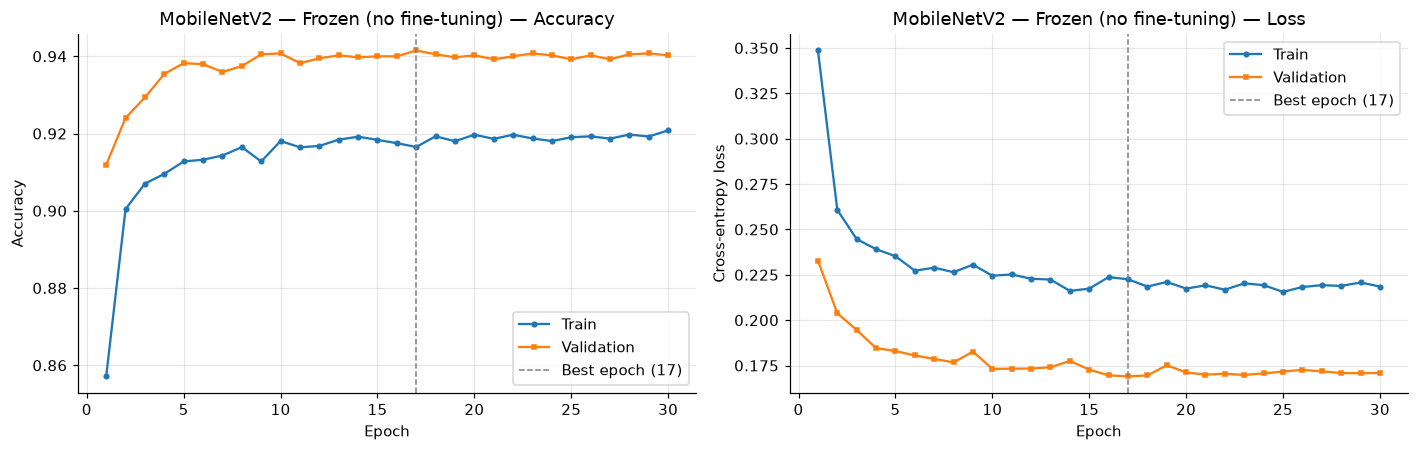


Classification report — MobileNetV2 — Frozen (no fine-tuning) (test set)

              precision    recall  f1-score   support

 Parasitized     0.9308    0.9143    0.9225      1972
  Uninfected     0.9160    0.9322    0.9240      1976

    accuracy                         0.9233      3948
   macro avg     0.9234    0.9232    0.9232      3948
weighted avg     0.9234    0.9233    0.9232      3948

ROC-AUC (Parasitized as positive): 0.9737


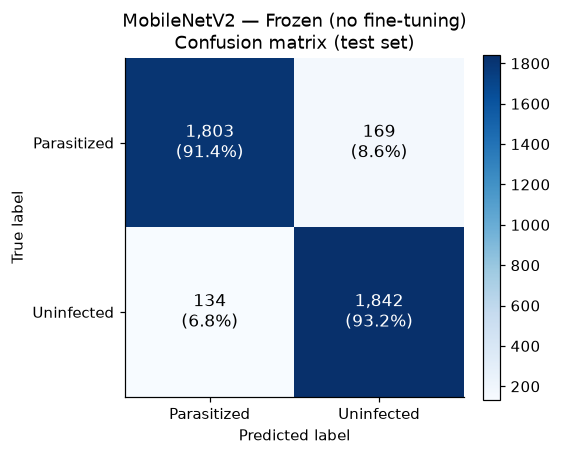

In [17]:
res_mobilenet_v2_frozen = run_experiment("mobilenet_v2", "frozen")

### 5.6 MobileNetV2 — with fine-tuning (all layers trained)

MobileNetV2 — Fine-tuned
Parameters: total 2,226,434 | trainable 2,226,434 (100.0%)
[mobilenet_v2_finetune] ep 01/40 | train loss 0.1634 acc 0.9406 | val loss 0.1081 acc 0.9661 | lr 1.0e-03 |  31.0s  *best*
[mobilenet_v2_finetune] ep 02/40 | train loss 0.1073 acc 0.9630 | val loss 0.1044 acc 0.9643 | lr 1.0e-03 |  14.5s  *best*
[mobilenet_v2_finetune] ep 03/40 | train loss 0.0953 acc 0.9663 | val loss 0.1068 acc 0.9610 | lr 1.0e-03 |  14.7s
[mobilenet_v2_finetune] ep 04/40 | train loss 0.0882 acc 0.9683 | val loss 0.0993 acc 0.9633 | lr 1.0e-03 |  14.6s  *best*
[mobilenet_v2_finetune] ep 05/40 | train loss 0.0857 acc 0.9694 | val loss 0.0880 acc 0.9699 | lr 1.0e-03 |  14.6s  *best*
[mobilenet_v2_finetune] ep 06/40 | train loss 0.0845 acc 0.9702 | val loss 0.0845 acc 0.9706 | lr 1.0e-03 |  14.6s  *best*
[mobilenet_v2_finetune] ep 07/40 | train loss 0.0768 acc 0.9720 | val loss 0.0896 acc 0.9681 | lr 1.0e-03 |  14.6s
[mobilenet_v2_finetune] ep 08/40 | train loss 0.0767 acc 0.9727 | val l

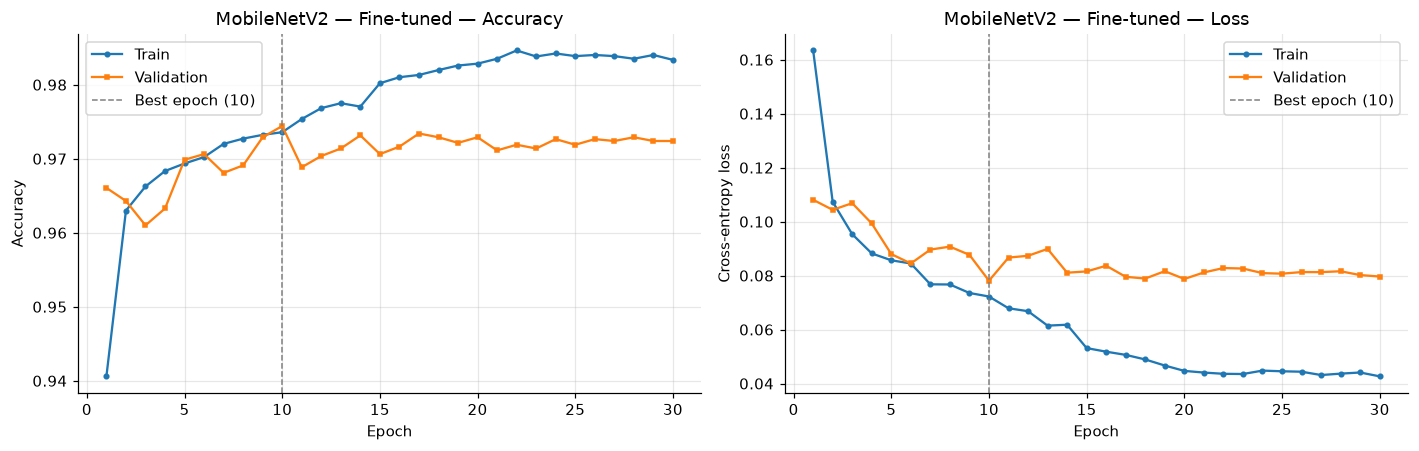


Classification report — MobileNetV2 — Fine-tuned (test set)

              precision    recall  f1-score   support

 Parasitized     0.9731    0.9726    0.9729      1972
  Uninfected     0.9727    0.9732    0.9729      1976

    accuracy                         0.9729      3948
   macro avg     0.9729    0.9729    0.9729      3948
weighted avg     0.9729    0.9729    0.9729      3948

ROC-AUC (Parasitized as positive): 0.9962


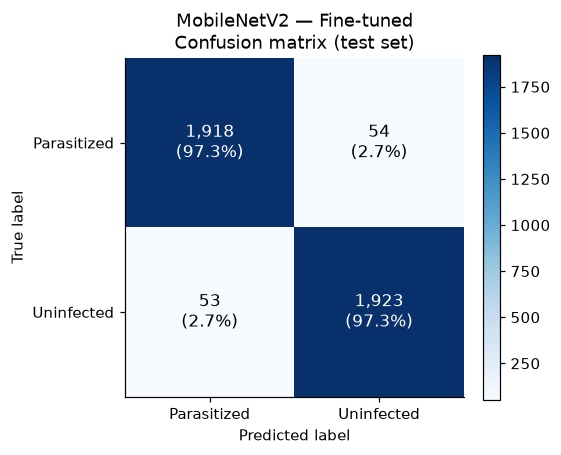

In [18]:
res_mobilenet_v2_finetune = run_experiment("mobilenet_v2", "finetune")

## 6. Results summary

The table below is generated from the saved results of all six runs, so it always matches the outputs above. Test-set metrics are shown in percent. The "Parasitized recall" column is the clinically most important number, because it measures how many infected cells the model catches.

In [19]:
rows = []
for arch in ARCHS:
    for mode in MODES:
        p = RESULTS_DIR / f"{arch}_{mode}.json"
        if p.exists():
            rows.append(json.load(open(p)))
assert rows, "No results found — run Section 5 first."
res = pd.DataFrame(rows)

table = pd.DataFrame({
    "Model": res.model,
    "Mode": res["mode"],
    "Trainable params": res.trainable_params.map(lambda v: f"{v / 1e6:.2f} M" if v >= 1e5 else f"{v:,}"),
    "Epochs (best)": [f"{e} ({b})" for e, b in zip(res.epochs_run, res.best_epoch)],
    "Train time (min)": (res.train_time_s / 60).round(1),
    "Test time (s)": res.test_time_s.round(2),
    "ms / image": res.ms_per_image.round(3),
    "Accuracy (%)": (100 * res.test_accuracy).round(2),
    "Precision (%)": (100 * res.macro_precision).round(2),
    "Recall (%)": (100 * res.macro_recall).round(2),
    "F1 (%)": (100 * res.macro_f1).round(2),
    "Parasitized recall (%)": (100 * res.recall_parasitized).round(2),
    "AUC": res.auc.round(4),
})

def to_markdown(df):
    head = "| " + " | ".join(df.columns) + " |"
    sep = "|" + "|".join(["---"] * len(df.columns)) + "|"
    body = ["| " + " | ".join(str(v) for v in row) + " |" for row in df.itertuples(index=False)]
    return "\n".join([head, sep] + body)

best = res.loc[res.macro_f1.idxmax()]
md_table = to_markdown(table)
display(Markdown("### Table: Test-set results for all models and modes\n\n" + md_table +
                 "\n\n*Precision, recall and F1 are macro-averaged over the two classes. Per-class values are in each run's classification report above.*"
                 f"\n\n**Best run by macro F1:** {best.model} — {best['mode']} "
                 f"(accuracy {100 * best.test_accuracy:.2f}%, F1 {100 * best.macro_f1:.2f}%)."))
table.to_csv(RESULTS_DIR / "summary_table.csv", index=False)
with open(RESULTS_DIR / "summary_table.md", "w") as f:
    f.write(md_table)

### Table: Test-set results for all models and modes

| Model | Mode | Trainable params | Epochs (best) | Train time (min) | Test time (s) | ms / image | Accuracy (%) | Precision (%) | Recall (%) | F1 (%) | Parasitized recall (%) | AUC |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| ResNet-50 | Frozen (no fine-tuning) | 4,098 | 33 (25) | 8.4 | 3.77 | 0.955 | 93.41 | 93.43 | 93.41 | 93.41 | 92.6 | 0.9781 |
| ResNet-50 | Fine-tuned | 23.51 M | 30 (8) | 14.4 | 3.14 | 0.795 | 97.29 | 97.29 | 97.29 | 97.29 | 97.16 | 0.9964 |
| DenseNet-121 | Frozen (no fine-tuning) | 2,050 | 39 (31) | 9.7 | 4.55 | 1.151 | 92.43 | 92.45 | 92.43 | 92.43 | 91.28 | 0.9757 |
| DenseNet-121 | Fine-tuned | 6.96 M | 30 (19) | 16.4 | 3.29 | 0.834 | 97.7 | 97.7 | 97.69 | 97.69 | 97.31 | 0.9968 |
| MobileNetV2 | Frozen (no fine-tuning) | 2,562 | 30 (17) | 6.9 | 4.37 | 1.106 | 92.33 | 92.34 | 92.32 | 92.32 | 91.43 | 0.9737 |
| MobileNetV2 | Fine-tuned | 2.23 M | 30 (10) | 7.6 | 3.17 | 0.802 | 97.29 | 97.29 | 97.29 | 97.29 | 97.26 | 0.9962 |

*Precision, recall and F1 are macro-averaged over the two classes. Per-class values are in each run's classification report above.*

**Best run by macro F1:** DenseNet-121 — Fine-tuned (accuracy 97.70%, F1 97.69%).

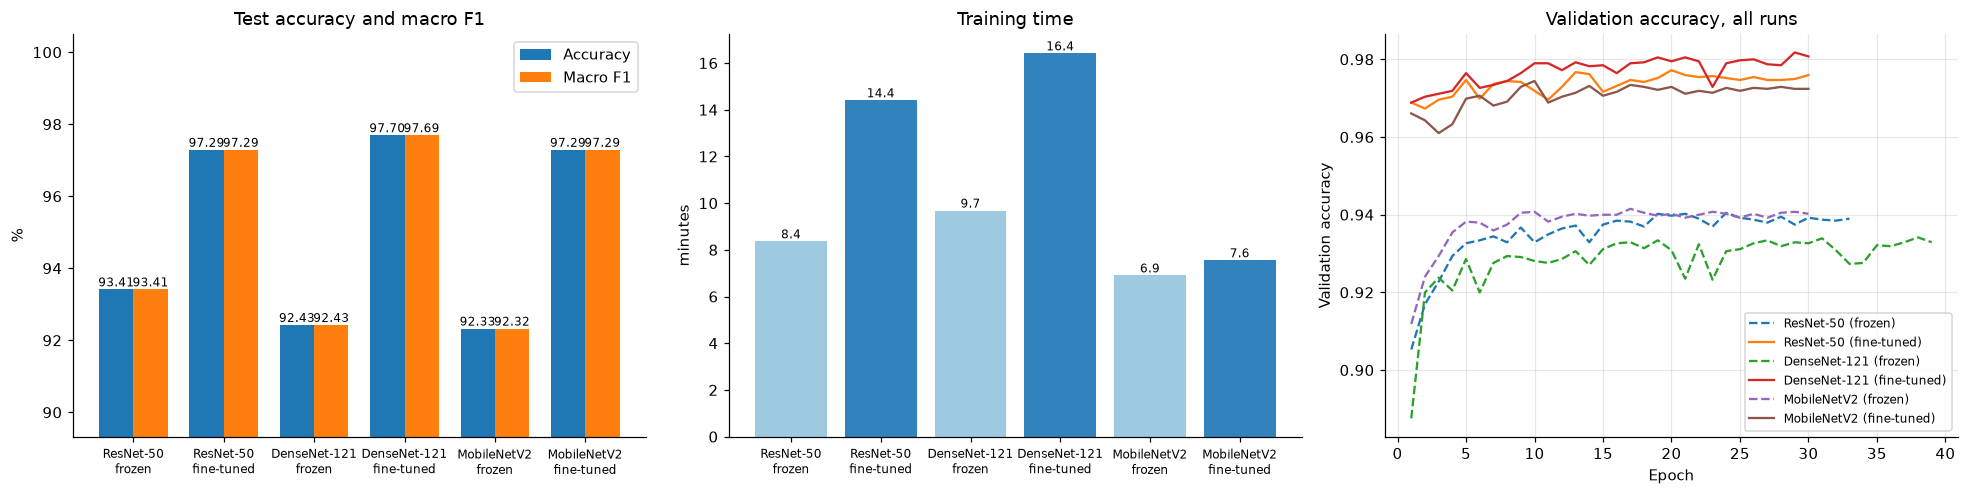

In [20]:
# Visual comparison: test accuracy / F1, training time, and validation curves of all six runs
fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
labels = [f"{m}\n{'frozen' if 'Frozen' in md_ else 'fine-tuned'}" for m, md_ in zip(res.model, res["mode"])]
x = np.arange(len(res)); w = 0.38
b1 = axes[0].bar(x - w / 2, 100 * res.test_accuracy, w, label="Accuracy")
b2 = axes[0].bar(x + w / 2, 100 * res.macro_f1, w, label="Macro F1")
axes[0].bar_label(b1, fmt="%.2f", fontsize=8); axes[0].bar_label(b2, fmt="%.2f", fontsize=8)
axes[0].set_xticks(x); axes[0].set_xticklabels(labels, fontsize=8)
axes[0].set_ylim(max(0, 100 * min(res.test_accuracy.min(), res.macro_f1.min()) - 3), 100.5)
axes[0].set_ylabel("%"); axes[0].set_title("Test accuracy and macro F1"); axes[0].legend()

b3 = axes[1].bar(x, res.train_time_s / 60, color=["#9ecae1" if "Frozen" in m else "#3182bd" for m in res["mode"]])
axes[1].bar_label(b3, fmt="%.1f", fontsize=8)
axes[1].set_xticks(x); axes[1].set_xticklabels(labels, fontsize=8)
axes[1].set_ylabel("minutes"); axes[1].set_title("Training time")

for _, r in res.iterrows():
    ls = "--" if "Frozen" in r["mode"] else "-"
    axes[2].plot(np.arange(1, len(r.history["val_acc"]) + 1), r.history["val_acc"], ls, label=f"{r.model} ({'frozen' if ls == '--' else 'fine-tuned'})")
axes[2].set_xlabel("Epoch"); axes[2].set_ylabel("Validation accuracy"); axes[2].set_title("Validation accuracy, all runs")
axes[2].grid(alpha=.3); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.savefig(FIG_DIR / "comparison.png"); plt.show()

### Discussion

**Fine-tuning vs. frozen feature extraction.** Fine-tuning clearly outperformed the frozen feature extractor for every architecture. Test accuracy rose by 3.88 points for ResNet-50 (93.41% → 97.29%), 5.27 points for DenseNet-121 (92.43% → 97.70%) and 4.96 points for MobileNetV2 (92.33% → 97.29%), and AUC rose from 0.974–0.978 to 0.996–0.997. With frozen ImageNet features, only a linear head of 2,050–4,098 parameters can learn, and those features were never trained on Giemsa-stained cells, so accuracy plateaus around 92–93%. Fine-tuning lets the deeper layers adapt to the small purple parasite texture.

**Architectures.** Once fine-tuned, all three models are within 0.41 points of each other. DenseNet-121 is the best overall (accuracy 97.70%, macro F1 97.69%, AUC 0.9968), which fits its dense feature reuse preserving fine, low-level detail. MobileNetV2 matches ResNet-50 exactly (97.29%) with about 10× fewer parameters (2.23 M vs 23.51 M) and about half the training time (7.6 vs 14.4 min), so it is a strong candidate for smartphone-microscope deployment. In frozen mode ResNet-50 was best (93.41%), likely because its 2,048-dimensional features are richer than DenseNet-121's 1,024 or MobileNetV2's 1,280.

**Cost.** Frozen runs took 6.9–9.7 min and fine-tuned runs 7.6–16.4 min. Peak GPU memory never exceeded 4.12 GB (DenseNet-121 fine-tuned), confirming that batch size 64 fits comfortably on the 12 GB RTX 4070. Test-set inference took 3.1–4.6 s for 3,948 images (0.8–1.2 ms per image). These times are dominated by CPU image loading and preprocessing, so they differ little between models.

**Over- and underfitting.** In the frozen runs, validation accuracy was slightly *above* training accuracy (gaps of −1.03 to −2.74 points at the best epoch), because augmentation and dropout are active only during training. The curves flatten after roughly 20 epochs, which indicates limited capacity (mild underfitting) rather than overfitting. The fine-tuned runs reached their lowest validation loss early (epochs 8, 19 and 10). After that, training loss kept falling while validation loss stopped improving, an early sign of overfitting. ReduceLROnPlateau lowered the learning rate, early stopping ended each run at epoch 30 (the minimum allowed), and the best-validation checkpoint was restored for testing. As a result, the train–validation gap at the selected epoch was only −0.08 to +0.30 points.

**Clinical view.** Recall on the Parasitized class matters most, because a missed infected cell is worse than a false alarm. DenseNet-121 fine-tuned had the highest Parasitized recall (97.31%), missing about 53 of 1,972 infected test cells. The frozen models missed roughly 146–172 (see the bottom-left cell of each confusion matrix).

**Comparison with the literature.** Our frozen ResNet-50 (93.41%) is below the 95.9% reported by Rajaraman et al. (2018), who selected the best *intermediate* layer for features, while we use the final pooled layer. Published fine-tuned results of up to 99.51% (Rajaraman et al., 2019) used different evaluation protocols. Our split groups cells by source smear photograph, which prevents near-duplicate context from leaking into the test set, so the numbers are not directly comparable.

**Benchmark for the next submissions.** Fine-tuned DenseNet-121 (97.70% accuracy, 97.69% F1) is the reference that our from-scratch CNN (Submission 3) and its attention-augmented version (Submission 4) will be compared against.